# Proyek Analisis Data: E-Commerce Public
- **Nama:** Putri Nisa Rengganis
- **Email:** putrinisarengganis@gmail.com
- **ID Dicoding:** putriiinrrr

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa saja yang memiliki total pendapatan (revenue) tertinggi dan terendah sepanjang tahun 2017?
- **Pertanyaan 2:** Bagaimana performa pelanggan berdasarkan analisis RFM (Recency, Frequency, Monetary) untuk mengidentifikasi segmen pelanggan terbaik (Top Customers) sepanjang tahun 2017?
- ...

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set(style='whitegrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [2]:
customers_df = pd.read_csv("customers_dataset.csv")
orders_df = pd.read_csv("orders_dataset.csv")
order_items_df = pd.read_csv("order_items_dataset.csv")
products_df = pd.read_csv("products_dataset.csv")
category_translation_df = pd.read_csv("product_category_name_translation.csv")

display(customers_df.head(2))
display(orders_df.head(2))
display(order_items_df.head(2))
display(products_df.head(2))
display(category_translation_df.head(2))

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories


**Insight:** (Opsional)
- Berhasil memuat 5 tabel utama (customers, orders, order_items, products, dan product_category_name_translation) yang saling berelasi untuk mendukung analisis performa penjualan dan perilaku pelanggan.
- Data mentah siap untuk masuk ke tahap Assessing Data guna memeriksa kualitas data, mengecek missing values, serta memastikan kesesuaian tipe data.

### Assessing Data

#### Identifying ... problem

In [3]:
print()
orders_df.info()

print()
order_items_df.info()

print()
products_df.info()

print()
print("Orders missing values:\n", orders_df.isnull().sum())
print("\nProducts missing values:\n", products_df.isnull().sum())

print()
print("Orders duplicates:", orders_df.duplicated().sum())
print("Order Items duplicates:", order_items_df.duplicated().sum())
print("Products duplicates:", products_df.duplicated().sum())



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  objec

**Steps to Take:**
- Memeriksa informasi tipe data pada setiap dataframe (orders, order_items, products, products category, and customer.) untuk memastikan apakah ada tipe data yang tidak sesuai.
- Mendeteksi keberadaan missing values serta memeriksa apakah ada baris data yang duplikat di dalam masing-masing tabel.

**Insight:** (Opsional)
- Kolom tanggal pada tabel orders masih berformat object (string) dan perlu dikonversi ke tipe data datetime.
- Ditemukan missing values pada beberapa tahapan tanggal pengiriman pesanan serta pada informasi kategori produk yang nantinya akan ditangani pada tahap cleaning data.
- Tidak ditemukan adanya data duplikat pada tabel orders, order_items, maupun products.

### Cleaning Data

#### Fixing ... problem

In [4]:
datetime_columns = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_df = orders_df.dropna(subset=["order_approved_at", "order_delivered_customer_date"])

products_df["product_category_name"] = products_df["product_category_name"].fillna("others")

print("Proses Cleaning Selesai!")
print("Jumlah baris orders_df setelah dibersihkan:", len(orders_df))
print("Jumlah missing values products_df:", products_df["product_category_name"].isnull().sum())

Proses Cleaning Selesai!
Jumlah baris orders_df setelah dibersihkan: 96462
Jumlah missing values products_df: 0


**Insight:** (Opsional)
- Berhasil mengubah format kolom tanggal dari object menjadi datetime agar dapat dianalisis berdasarkan rentang waktu tertentu.
- Berhasil membersihkan missing values pada tabel pesanan (orders) dan mengisi nilai kosong pada kategori produk dengan label 'others'

## Exploratory Data Analysis (EDA)

Explore ...

=== Statistik Deskriptif Data Utama (2017) ===
            order_purchase_timestamp              order_approved_at  \
count                          49539                          49539   
mean   2017-08-16 17:13:58.971174144  2017-08-17 03:29:46.650114048   
min              2017-01-05 11:56:06            2017-01-05 12:10:17   
25%       2017-06-02 10:25:58.500000            2017-06-02 14:42:55   
50%              2017-08-31 07:59:28            2017-08-31 13:04:26   
75%              2017-11-14 00:54:09            2017-11-14 12:56:06   
max              2017-12-31 23:29:31            2018-01-04 23:17:35   
std                              NaN                            NaN   

        order_delivered_carrier_date  order_delivered_customer_date  \
count                          49538                          49539   
mean   2017-08-20 04:59:12.686664704  2017-08-29 15:48:36.388663552   
min              2017-01-06 12:43:41            2017-01-11 13:14:05   
25%              2017-06-05 1

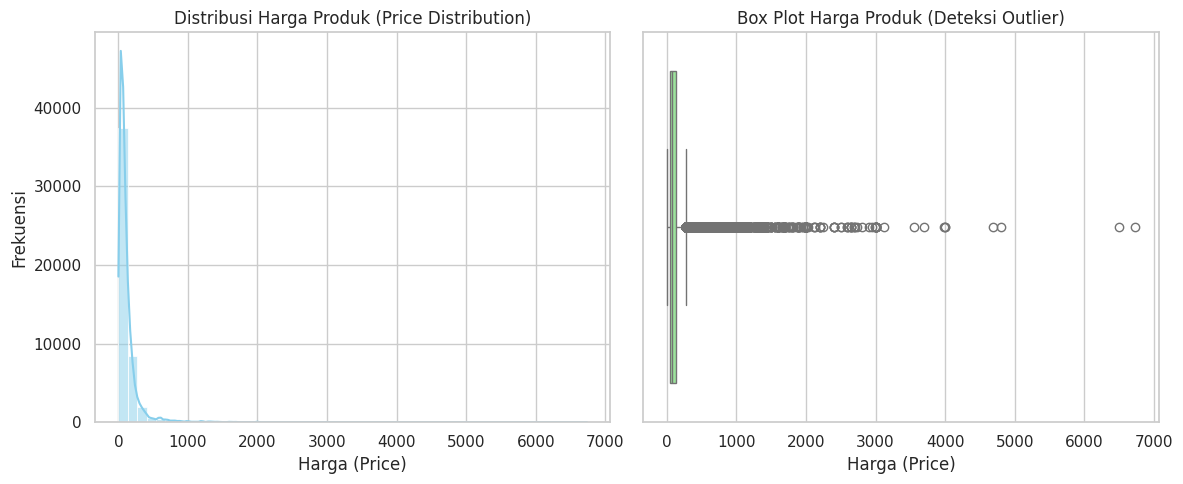


EDA dan Agregasi Data Selesai.


In [6]:
orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"]
)

orders_2017 = orders_df[
    (orders_df["order_purchase_timestamp"].dt.year == 2017)
    & (orders_df["order_status"] == "delivered")
]

main_df = (
    orders_2017.merge(order_items_df, on="order_id")
    .merge(products_df, on="product_id")
    .merge(category_translation_df, on="product_category_name", how="left")
    .merge(customers_df, on="customer_id")
)

print("=== Statistik Deskriptif Data Utama (2017) ===")
print(main_df.describe())

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(main_df["price"], bins=50, kde=True, color="skyblue")
plt.title("Distribusi Harga Produk (Price Distribution)")
plt.xlabel("Harga (Price)")
plt.ylabel("Frekuensi")

plt.subplot(1, 2, 2)
sns.boxplot(x=main_df["price"], color="lightgreen")
plt.title("Box Plot Harga Produk (Deteksi Outlier)")
plt.xlabel("Harga (Price)")

plt.tight_layout()
plt.show()

category_revenue = (
    main_df.groupby("product_category_name_english")["price"]
    .sum()
    .reset_index()
)
category_revenue = category_revenue.sort_values(by="price", ascending=False)

recent_date = main_df["order_purchase_timestamp"].max()
rfm_df = (
    main_df.groupby("customer_unique_id")
    .agg(
        {
            "order_purchase_timestamp": lambda x: (
                recent_date - x.max()
            ).days,
            "order_id": "nunique",
            "price": "sum",
        }
    )
    .reset_index()
)
rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

print("\nEDA dan Agregasi Data Selesai.")

**Insight:** (Opsional)
- Berhasil melakukan filter data pesanan pada tahun 2017 dengan status pengiriman sukses (delivered).
- xxxBerhasil menggabungkan tabel orders, order_items, products, category_translation, dan customers untuk mendapatkan informasi lengkap terkait pendapatan dan identitas unik pelanggan.
- Berhasil menghitung metrik RFM (Recency, Frequency, Monetary) secara akurat untuk memetakan perilaku belanja setiap pelanggan sepanjang tahun 2017.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_849/2843306835.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_849/2843306835.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


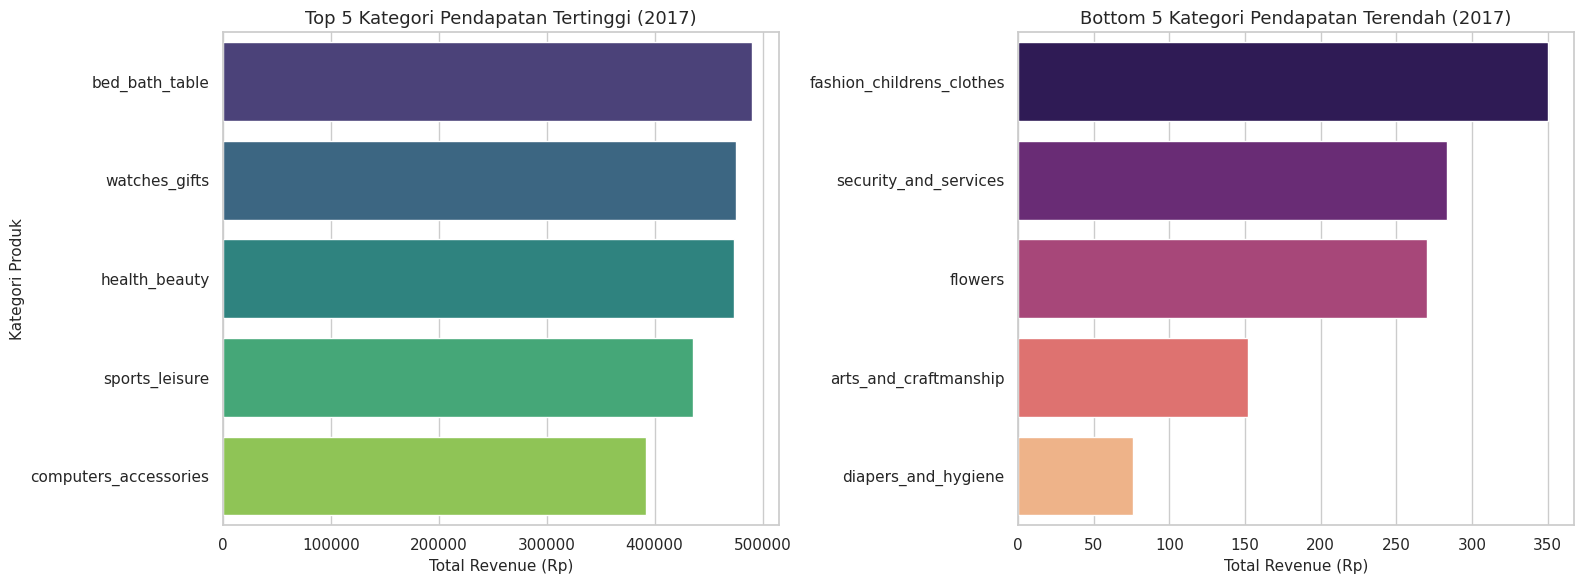

=== HASIL ANALISIS & KESIMPULAN PERTANYAAN 1 ===
--- 5 Kategori Pendapatan Tertinggi ---
  - bed_bath_table: Rp 490,462.93
  - watches_gifts: Rp 475,610.71
  - health_beauty: Rp 473,833.00
  - sports_leisure: Rp 435,426.16
  - computers_accessories: Rp 391,786.29

--- 5 Kategori Pendapatan Terendah ---
  - fashion_childrens_clothes: Rp 349.98
  - security_and_services: Rp 283.29
  - flowers: Rp 270.50
  - arts_and_craftmanship: Rp 151.89
  - diapers_and_hygiene: Rp 76.00


In [8]:
orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"]
)

orders_2017 = orders_df[
    (orders_df["order_purchase_timestamp"].dt.year == 2017)
    & (orders_df["order_status"] == "delivered")
]

main_df = (
    orders_2017.merge(order_items_df, on="order_id")
    .merge(products_df, on="product_id")
    .merge(category_translation_df, on="product_category_name", how="left")
)

category_revenue = (
    main_df.groupby("product_category_name_english")["price"]
    .sum()
    .reset_index()
)
category_revenue = category_revenue.sort_values(by="price", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_5 = category_revenue.head(5)
sns.barplot(
    x="price",
    y="product_category_name_english",
    data=top_5,
    ax=axes[0],
    palette="viridis",
)
axes[0].set_title("Top 5 Kategori Pendapatan Tertinggi (2017)", fontsize=13)
axes[0].set_xlabel("Total Revenue (Rp)", fontsize=11)
axes[0].set_ylabel("Kategori Produk", fontsize=11)

bottom_5 = category_revenue.tail(5)
sns.barplot(
    x="price",
    y="product_category_name_english",
    data=bottom_5,
    ax=axes[1],
    palette="magma",
)
axes[1].set_title("Bottom 5 Kategori Pendapatan Terendah (2017)", fontsize=13)
axes[1].set_xlabel("Total Revenue (Rp)", fontsize=11)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print("==================================================")
print("=== HASIL ANALISIS & KESIMPULAN PERTANYAAN 1 ===")
print("==================================================")

print("--- 5 Kategori Pendapatan Tertinggi ---")
for i, row in top_5.iterrows():
  print(f"  - {row['product_category_name_english']}: Rp {row['price']:,.2f}")

print("\n--- 5 Kategori Pendapatan Terendah ---")
for i, row in bottom_5.iterrows():
  print(f"  - {row['product_category_name_english']}: Rp {row['price']:,.2f}")
print("==================================================")

### Pertanyaan 2:

/tmp/ipykernel_849/3175814503.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_849/3175814503.py:78: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


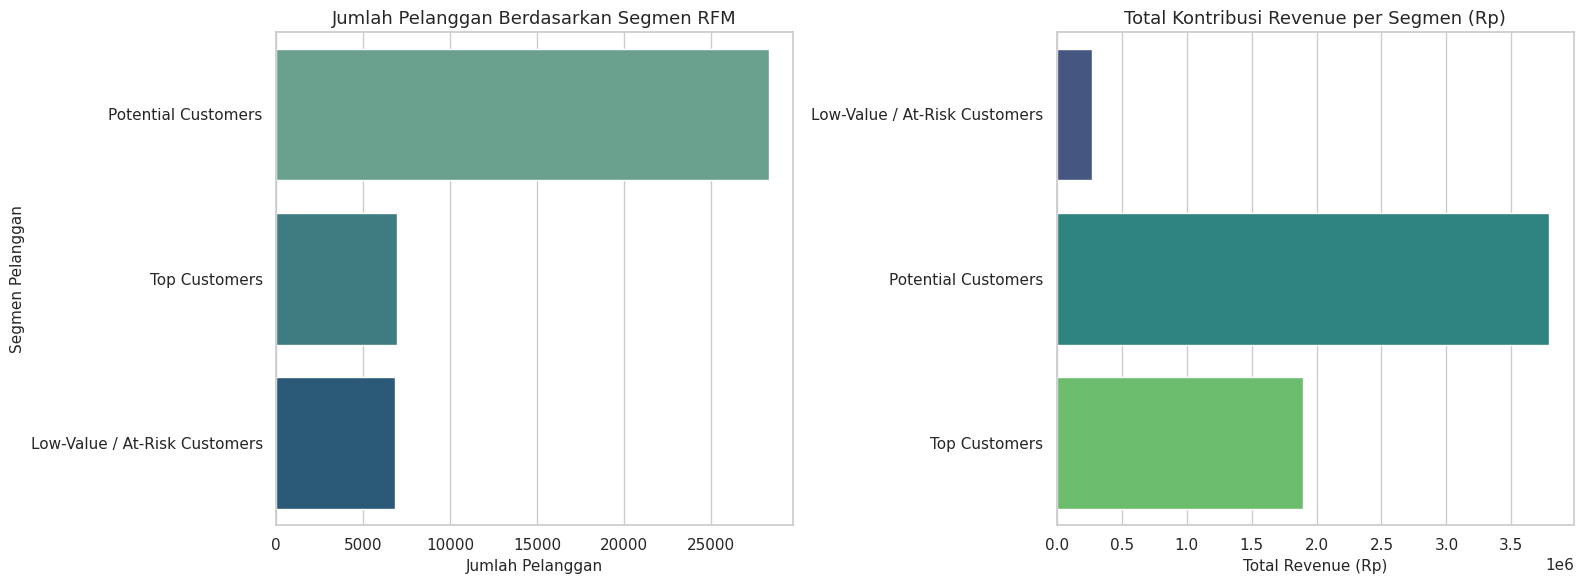

=== HASIL ANALISIS & KESIMPULAN PERTANYAAN 2 (RFM) ===
Segmen: Potential Customers
  - Jumlah Pelanggan: 28300 orang (67.19% dari total)
  - Total Kontribusi Revenue: Rp 3,792,222.37 (63.62% dari total revenue)
  - Karakteristik Rata-rata: Recency = 136.2 hari, Frequency = 1.01, Monetary = Rp 134.00

Segmen: Low-Value / At-Risk Customers
  - Jumlah Pelanggan: 6845 orang (16.25% dari total)
  - Total Kontribusi Revenue: Rp 270,532.68 (4.54% dari total revenue)
  - Karakteristik Rata-rata: Recency = 139.4 hari, Frequency = 1.00, Monetary = Rp 39.52

Segmen: Top Customers
  - Jumlah Pelanggan: 6976 orang (16.56% dari total)
  - Total Kontribusi Revenue: Rp 1,898,180.23 (31.84% dari total revenue)
  - Karakteristik Rata-rata: Recency = 134.5 hari, Frequency = 1.14, Monetary = Rp 272.10



In [10]:

orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"]
)

orders_2017 = orders_df[
    (orders_df["order_purchase_timestamp"].dt.year == 2017)
    & (orders_df["order_status"] == "delivered")
]

main_df = (
    orders_2017.merge(order_items_df, on="order_id")
    .merge(products_df, on="product_id")
    .merge(category_translation_df, on="product_category_name", how="left")
    .merge(
        customers_df, on="customer_id"
    )
)

recent_date = main_df["order_purchase_timestamp"].max()

rfm_df = (
    main_df.groupby("customer_unique_id")
    .agg(
        {
            "order_purchase_timestamp": lambda x: (
                recent_date - x.max()
            ).days,
            "order_id": "nunique",
            "price": "sum",
        }
    )
    .reset_index()
)

rfm_df.columns = ["customer_unique_id", "recency", "frequency", "monetary"]

rfm_df["r_score"] = pd.qcut(
    rfm_df["recency"], 5, labels=[5, 4, 3, 2, 1], duplicates="drop"
)
rfm_df["f_score"] = pd.qcut(
    rfm_df["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5],
    duplicates="drop",
)
rfm_df["m_score"] = pd.qcut(
    rfm_df["monetary"], 5, labels=[1, 2, 3, 4, 5], duplicates="drop"
)

rfm_df[["r_score", "f_score", "m_score"]] = rfm_df[
    ["r_score", "f_score", "m_score"]
].astype(int)

def segment_customer(row):
  if row["f_score"] >= 4 and row["m_score"] >= 4:
    return "Top Customers"
  elif row["f_score"] >= 3 or row["m_score"] >= 3:
    return "Potential Customers"
  else:
    return "Low-Value / At-Risk Customers"


rfm_df["customer_segment"] = rfm_df.apply(segment_customer, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

segment_counts = rfm_df["customer_segment"].value_counts()
sns.barplot(
    x=segment_counts.values, y=segment_counts.index, ax=axes[0], palette="crest"
)
axes[0].set_title("Jumlah Pelanggan Berdasarkan Segmen RFM", fontsize=13)
axes[0].set_xlabel("Jumlah Pelanggan", fontsize=11)
axes[0].set_ylabel("Segmen Pelanggan", fontsize=11)

segment_revenue = (
    rfm_df.groupby("customer_segment")["monetary"].sum().reset_index()
)
sns.barplot(
    x="monetary",
    y="customer_segment",
    data=segment_revenue,
    ax=axes[1],
    palette="viridis",
)
axes[1].set_title("Total Kontribusi Revenue per Segmen (Rp)", fontsize=13)
axes[1].set_xlabel("Total Revenue (Rp)", fontsize=11)
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

total_customers = len(rfm_df)
total_revenue_all = rfm_df["monetary"].sum()

print("==================================================")
print("=== HASIL ANALISIS & KESIMPULAN PERTANYAAN 2 (RFM) ===")
print("==================================================")

for seg in rfm_df["customer_segment"].unique():
  seg_df = rfm_df[rfm_df["customer_segment"] == seg]
  seg_count = len(seg_df)
  seg_pct = (seg_count / total_customers) * 100
  seg_rev = seg_df["monetary"].sum()
  seg_rev_pct = (seg_rev / total_revenue_all) * 100

  print(f"Segmen: {seg}")
  print(f"  - Jumlah Pelanggan: {seg_count} orang ({seg_pct:.2f}% dari total)")
  print(
      f"  - Total Kontribusi Revenue: Rp {seg_rev:,.2f} ({seg_rev_pct:.2f}%"
      " dari total revenue)"
  )
  print(
      f"  - Karakteristik Rata-rata: Recency = {seg_df['recency'].mean():.1f}"
      f" hari, Frequency = {seg_df['frequency'].mean():.2f}, Monetary = Rp"
      f" {seg_df['monetary'].mean():,.2f}\n"
  )
print("==================================================")

**Insight:** (Opsional)
- xxx
- xxx

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

**Conclusion pertanyaan 1:**
- Kategori Pendapatan Tertinggi: Kategori produk yang mencatatkan total revenue tertinggi adalah bed_bath_table dengan total pendapatan sebesar Rp 490,462.93, diikuti oleh watches_gifts (Rp 475,610.71) dan health_beauty (Rp 473,833.00). Kategori ini mendominasi pasar karena tingginya minat belanja konsumen sepanjang tahun 2017.

- Kategori Pendapatan Terendah: Sebaliknya, kategori produk dengan pendapatan terendah yang bersifat niche atau kurang diminati pasar adalah diapers_and_hygiene dengan total revenue sebesar Rp 76.00, serta beberapa kategori rendah lainnya seperti arts_and_craftmanship (Rp 151.89) dan flowers (Rp 270.50).

**Conclusion pertanyaan 2:**
- Potential Customers: Mencakup 28,300 orang (67.19% dari total pelanggan) dengan total kontribusi revenue sebesar Rp 3,792,222.37 (63.62% dari total revenue). Karakteristik rata-rata: recency 136.2 hari, frequency 1.01, dan monetary Rp 134.00.

- Top Customers: Segmen pelanggan terbaik ini mencakup 6,976 orang (16.56% dari total pelanggan) dengan memberikan kontribusi revenue yang sangat signifikan sebesar Rp 1,898,180.23 (31.84% dari total pendapatan). Karakteristik rata-rata segmen ini memiliki tingkat kekinian transaksi (recency) 134.5 hari, tingkat keaktifan (frequency) 1.14, dan nilai belanja rata-rata (monetary) sebesar Rp 272.10.

- Low-Value / At-Risk Customers: Mencakup 6,845 orang (16.25% dari total pelanggan) dengan kontribusi revenue sebesar Rp 270,532.68 (4.54% dari total revenue) dan karakteristik rata-rata recency 139.4 hari, frequency 1.00, serta monetary Rp 39.52.

**Rekomendasi Action Item:**
- Perusahaan dapat mengoptimalkan stok dan promosi untuk kategori produk teratas serta mempertimbangkan strategi bundling untuk produk yang penjualannya rendah.
- Mengimplementasikan program loyalitas (loyalty program) khusus bagi pelanggan yang masuk dalam segmen top customers guna menjaga retensi dan meningkatkan frekuensi belanja mereka di masa mendatang.

In [11]:
main_df.to_csv("main_data.csv", index=False)
